In [313]:
import numpy as np
import matplotlib.pyplot as plt

In [314]:
def piecewise_cubic_interpolation(x_data, y_data, x_interp):
  """
  Performs piecewise cubic interpolation without overlapping subintervals.
  x_data: List or array of x values (must be sorted)
  y_data: List or array of corresponding y values
  x_interp: The x value where interpolation is needed
  return: Interpolated value at x_interp and piecewise cubic polynomials
  """
  if len(x_data) < 4 or len(x_data)%3 != 1:
    raise ValueError("Number of points must be 4, 7, 10 etc. for non-overlapping cubic interpolation.")
  if not np.all(np.diff(x_data) > 0):
    raise ValueError("x_data must be in strictly increasing order.")
  polynomials = []
  for i in range(0, len(x_data)-3, 3):
    x0, x1, x2, x3 = x_data[i], x_data[i+1], x_data[i+2], x_data[i+3]
    y0, y1, y2, y3 = y_data[i], y_data[i+1], y_data[i+2], y_data[i+3]
    # Solve for coefficients a, b, c, d in P(x) = ax^3+bx^2+cx+d
    A = np.array([
        [x0**3, x0**2, x0, 1],
        [x1**3, x1**2, x1, 1],
        [x2**3, x2**2, x2, 1],
        [x3**3, x3**2, x3, 1]
    ])
    B = np.array([y0, y1, y2, y3])
    coeffs = np.linalg.solve(A, B)    # Solve linear systems
    a, b, c, d = coeffs
    polynomials.append((a, b, c, d, (x0, x3)))
  # Print all calculated polynomials
  print("Calculated Piecewise Cubic Polynomials")
  for i, (a, b, c, d, (x0, x3)) in enumerate(polynomials):
    print(f"P{i}(x) = {a:.2f}x^3 + {b:.2f}x^2 + {c:.2f}x + {d:.2f}, for x in [{x0}, {x3}]")
  # Find the interval where x_interp falls
  y_interp = None
  for a, b, c, d, (x0, x3) in polynomials:
    if x0 <= x_interp <= x3:
      y_interp = a * x_interp**3 + b * x_interp**2 + c * x_interp + d
      break
  return y_interp, polynomials

In [315]:
def plot_interpolation(x_data, y_data, polynomials, x_interp=None, y_interp=None):
  """Plots the piecewise cubic interpolation."""
  plt.figure(figsize=(8, 6))
  # Plot the piecewise cubic segments
  for a, b, c, d, (x0, x3) in polynomials:
    x_vals = np.linspace(x0, x3, 100)
    y_vals = a * x_vals**3 + b * x_vals**2 + c * x_vals + d
    plt.plot(x_vals, y_vals, 'b-', label=f'P(x) = {a:.2f}x^3 + {b:.2f}x^2 + {c:.2f}x + d' if x0 == x_data[0] else '')
  # Scatter plot of given data points
  plt.scatter(x_data, y_data, color='red', label='Given Data Points')
  # Highlight interpolated point
  if x_interp is not None and y_interp is not None:
    plt.scatter(x_interp, y_interp, color='green', label=f'Interpolated Point ({x_interp:.2f}, {y_interp:.2f})', zorder=3)
  plt.xlabel('x')
  plt.ylabel('P(x)')
  plt.legend()
  plt.title('Piecewise Cubic Interpolation')
  plt.grid()
  plt.show()

In [316]:
# Example Usage
x_data = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])    # Given x points
y_data = np.array([2, 4, 1, 3, 7, 8, 5, 6, 1, 4])    # Given y points
x_interp = 8.5                        # Point to interpolate

In [317]:
y_interp, polynomials = piecewise_cubic_interpolation(x_data, y_data, x_interp)
print(f'Interpolated value at x = {x_interp}: {y_interp}')

Calculated Piecewise Cubic Polynomials
P0(x) = 1.67x^3 + -12.50x^2 + 27.83x + -15.00, for x in [1, 4]
P1(x) = -0.17x^3 + 1.00x^2 + 5.17x + -23.00, for x in [4, 7]
P2(x) = 2.33x^3 + -59.00x^2 + 491.67x + -1346.00, for x in [7, 10]
Interpolated value at x = 8.5: 3.3750000000002274


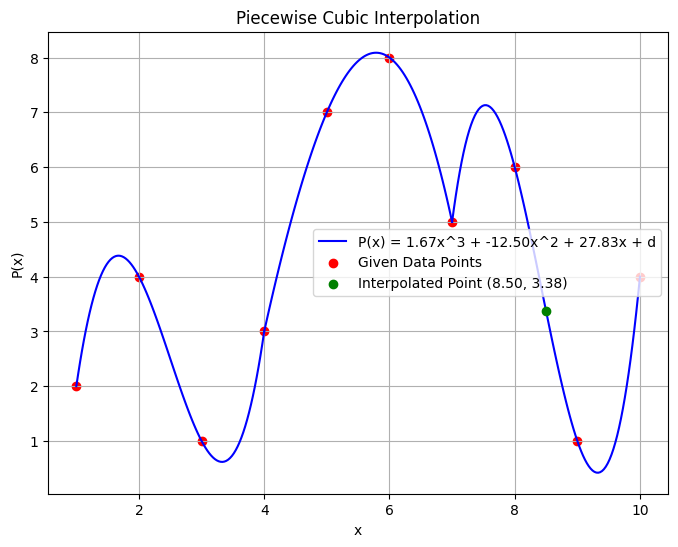

In [318]:
# Plot the interpolation
plot_interpolation(x_data, y_data, polynomials, x_interp, y_interp)